# Part 4: Demand forecasting
Forecasts hourly pickups 7 days ahead for the top 50 zones plus one "other zones" series per borough. Compares seasonal naive, MSTL and a global LightGBM in a 12-week rolling-origin backtest scored by MASE and WAPE, then saves next week's forecast for the dashboard.

Part of [NYC Yellow Cab: demand, pricing and forecasting](../README.md). Next: [Part 5, dashboard](P5_dashboard.ipynb).

In [13]:
!pip install -q duckdb lightgbm statsforecast holidays
import os, sys, json, time
from pathlib import Path
import duckdb, pandas as pd, numpy as np
import lightgbm as lgb
import holidays
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from statsforecast import StatsForecast
from statsforecast.models import MSTL, SeasonalNaive, AutoETS

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

BASE = Path(os.environ.get("NYC_TAXI_BASE", "/content/drive/MyDrive/nyc-yellow-cab"))
AGG, MODELS, FIG = BASE / "agg", BASE / "models", BASE / "figures"
MODELS.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
con = duckdb.connect(str(BASE / "taxi.duckdb"), read_only=True)

TOP_N = 50              # zones forecast on their own; the rest are grouped by borough
H = 168                 # forecast horizon: 7 days of hours
N_WINDOWS = 12          # backtest: 12 one-week windows, the last 12 weeks of data
MSTL_INPUT_WEEKS = 8    # MSTL fits on the 8 weeks before each cutoff (more is slow and barely helps)
SEED = 42

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "lines.linewidth": 2,
    "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=C),
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
# 4.1 Build series, top 50 zones
series = con.sql(f"""
  WITH totals AS (
    SELECT zone, SUM(pickups) AS n
    FROM demand_zone_hour
    GROUP BY 1),
  top AS (SELECT zone FROM totals ORDER BY n DESC LIMIT {TOP_N}),
  labels AS(
    SELECT LocationID AS zone, Borough AS borough,
    CASE WHEN LocationID IN (SELECT zone FROM top) THEN 'z' || LocationID ELSE 'other_' || Borough END AS unique_id,
    CASE WHEN LocationID IN (SELECT zone FROM top) THEN Zone ELSE Borough || ' (other zones)' END AS label
  FROM zones)
  SELECT l.unique_id, ANY_VALUE(l.label) AS label, ANY_VALUE(l.borough) AS borough,
           d.hour_ts AS ds, SUM(d.pickups)::DOUBLE AS y
  FROM demand_zone_hour d
  JOIN labels l USING (zone)
  GROUP BY l.unique_id, d.hour_ts
  ORDER BY l.unique_id, d.hour_ts
  """).df()

info = series.groupby("unique_id")[["label", "borough"]].first()
LABEL, BOROUGH = info.label.to_dict(), info.borough.to_dict()
share = series.loc[series.unique_id.str.startswith("z"), "y"].sum() / series.y.sum()
hours_per_series = series.groupby("unique_id").size()
assert hours_per_series.nunique() == 1, "series have different lengths: demand grid isn't complete"
print(f"{series.unique_id.nunique()} series × {hours_per_series.iloc[0]:,} hours "
      f"({series.ds.min():%Y-%m-%d} to {series.ds.max():%Y-%m-%d}); top {TOP_N} zones hold {share:.0%} of pickups")

56 series × 17,520 hours (2024-09-01 to 2026-08-31); top 50 zones hold 92% of pickups


In [15]:
# 4.2 Seasonal naive and MSTL
sf = StatsForecast(
    models=[SeasonalNaive(season_length=H),
            MSTL(season_length=[24, H], trend_forecaster=AutoETS(model="ZZN"))],
    freq='h', n_jobs=-1)
t0 = time.time()
cv = sf.cross_validation(df=series[['unique_id', 'ds', 'y']], h=H, step_size=H, n_windows=N_WINDOWS,
                         input_size=MSTL_INPUT_WEEKS * H)
cv = cv.rename(columns={"SeasonalNaive": "Seasonal naive"})
cv['MSTL'] = cv.MSTL.clip(lower=0)  # demand cannot be negative
CUTOFFS = sorted(cv.cutoff.unique())
print(f"{len(CUTOFFS)} windows, first cutoff {CUTOFFS[0]}, last {CUTOFFS[-1]} ({time.time() - t0:.0f} s)")

12 windows, first cutoff 2026-06-08 23:00:00, last 2026-08-24 23:00:00 (81 s)


In [16]:
# 4.3 LightGBM features
hol = set(holidays.US(subdiv='NY', years=range(series.ds.dt.year.min(), series.ds.dt.year.max() + 2)))
def add_features(panel):
  panel = panel.sort_values(['unique_id', 'ds'], ignore_index=True)
  g = panel.groupby('unique_id', observed=True)['y']
  for lag in (168, 336, 504, 672):
    panel[f'lag_{lag}'] = g.shift(lag)
  panel['same_hour_4wk_mean'] = panel[['lag_168','lag_336','lag_504','lag_672']].mean(axis=1)
  week_ago = g.shift(168)
  wg = week_ago.groupby(panel.unique_id, observed=True)
  panel["day_mean_week_ago"] = wg.transform(lambda s: s.rolling(24).mean())      # level of the day a week back
  panel["week_mean_week_ago"] = wg.transform(lambda s: s.rolling(168).mean())    # level of the week a week back
  panel["hour"] = panel.ds.dt.hour
  panel["dow"] = panel.ds.dt.dayofweek
  panel["month"] = panel.ds.dt.month
  panel["is_holiday"] = panel.ds.dt.date.isin(hol).astype(int)
  panel["holiday_week_ago"] = (panel.ds - pd.Timedelta(days=7)).dt.date.isin(hol).astype(int)  # lag_168 was a holiday
  panel["post_cp"] = (panel.ds >= "2025-01-05").astype(int)
  panel["series"] = panel.unique_id.astype("category")
  return panel

FEATURES = ["series", "hour", "dow", "month", "is_holiday", "holiday_week_ago", "post_cp",
            "lag_168", "lag_336", "lag_504", "lag_672", "same_hour_4wk_mean",
            "day_mean_week_ago", "week_mean_week_ago"]

LGB_PARAMS = dict(objective="poisson", learning_rate=0.05, num_leaves=63, min_data_in_leaf=100,
                  feature_fraction=0.9, bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=SEED)
NUM_ROUNDS = 600

panel = add_features(series[["unique_id", "ds", "y"]])
print(f"{len(panel):,} rows, {panel.lag_672.notna().mean():.0%} with a full 4-week history")


981,120 rows, 96% with a full 4-week history


In [17]:
# 4.4 Backtesting
def lgb_backtest(train_start=None):
  out = []
  for c in CUTOFFS:
    tr = panel[(panel.ds <= c) & panel.lag_672.notna()]
    if train_start is not None:
      tr = tr[tr.ds >= train_start]
    te = panel[(panel.ds >= c) & (panel.ds <= c + pd.Timedelta(hours=H))]
    model = lgb.train(LGB_PARAMS, lgb.Dataset(tr[FEATURES], tr.y), num_boost_round=NUM_ROUNDS)
    out.append(te[['unique_id','ds']].assign(cutoff=c, pred=model.predict(te[FEATURES])))
  return pd.concat(out), model

t0 = time.time()
lgb_all, _ = lgb_backtest()
lgb_post, _ = lgb_backtest(train_start="2025-01-05")
print(f"LightGBM backtests done ({time.time() - t0:.0f} s)")

cv = (cv.merge(lgb_all.rename(columns={"pred": "LightGBM"}), on=["unique_id", "ds", "cutoff"])
        .merge(lgb_post.rename(columns={"pred": "LightGBM (post-Jan 2025 data)"}), on=["unique_id", "ds", "cutoff"]))
MODEL_COLS = ["Seasonal naive", "MSTL", "LightGBM", "LightGBM (post-Jan 2025 data)"]
assert cv[MODEL_COLS].notna().all().all() and len(cv) == series.unique_id.nunique() * H * N_WINDOWS
cv["borough"] = cv.unique_id.map(BOROUGH)

LightGBM backtests done (461 s)


In [18]:
# 4.5 MASE (Mean Absolute Scaled Error) divides each series’ error by the error of “same hour last week” on
# its own history, so below 1 beats seasonal naive and every zone counts equally. WAPE (Weighted Absolute
# Percentage Error) is total error divided by total pickups, so busy zones count more.
hist = series[series.ds <= CUTOFFS[0]].sort_values(['unique_id', 'ds'])
scale = (hist.y - hist.groupby('unique_id').y.shift(H)).abs().groupby(hist.unique_id).mean() # abs difference between H averaged by zone

def scores(frame):
  err = {m: (frame[m] - frame.y).abs() for m in MODEL_COLS} # element-wise absolute error for each model
  mase = {m: (e.groupby(frame.unique_id).mean() / scale).mean() for m, e in err.items()}
  wape = {m: e.sum() / frame.y.sum() for m, e in err.items()}
  return pd.DataFrame({"MASE": mase, "WAPE": wape})

overall = scores(cv)
overall['MAE (pickups/hour)'] = [(cv[m] - cv.y).abs().mean() for m in MODEL_COLS]
by_borough = pd.concat({b: scores(f) for b, f in cv.groupby('borough')}, names=['borough', 'model'])
week_start = (cv.cutoff + pd.Timedelta(hours=1)).dt.strftime("%b %d") # a window starts the hour after its cutoff
# WAPE for every model during each testing week
# by_week = cv.assign(week=week_start).groupby("week", sort=False).apply(
#     lambda f: pd.Series({m: (f[m] - f.y).abs().sum() / f.y.sum() for m in MODEL_COLS}))
grouped = cv.assign(week=week_start).groupby('week', sort=False)
abs_errors = grouped[MODEL_COLS].apply(lambda x: x.sub(cv['y'], axis=0).abs().sum())
sum_y = grouped['y'].sum()
by_week = abs_errors.div(sum_y, axis=0)

display(overall.round(3)) if "display" in globals() else print(overall.round(3))
display(by_borough.WAPE.unstack().round(3)) if "display" in globals() else print(by_borough.WAPE.unstack().round(3))
BEST = overall.MASE.drop("Seasonal naive").idxmin()
naive = overall.loc["Seasonal naive"]
print(f"Best model: {BEST}, MASE {overall.MASE[BEST]:.3f} vs. {naive.MASE:.3f} for seasonal naive "
      f"({1 - overall.MASE[BEST] / naive.MASE:.0%} lower), WAPE {overall.WAPE[BEST]:.1%} vs. {naive.WAPE:.1%}")

                                MASE   WAPE  MAE (pickups/hour)
Seasonal naive                 0.895  0.221              17.571
MSTL                           0.888  0.225              17.956
LightGBM                       0.735  0.177              14.103
LightGBM (post-Jan 2025 data)  0.733  0.177              14.078
model          Seasonal naive   MSTL  LightGBM  LightGBM (post-Jan 2025 data)
borough                                                                      
Bronx                   0.554  0.566     0.563                          0.560
Brooklyn                0.296  0.314     0.280                          0.278
EWR                     1.788  2.331     3.085                          3.020
Manhattan               0.212  0.216     0.168                          0.167
Queens                  0.266  0.271     0.218                          0.219
Staten Island           1.416  1.339     1.405                          1.427
Best model: LightGBM (post-Jan 2025 data), MASE 0.733 vs

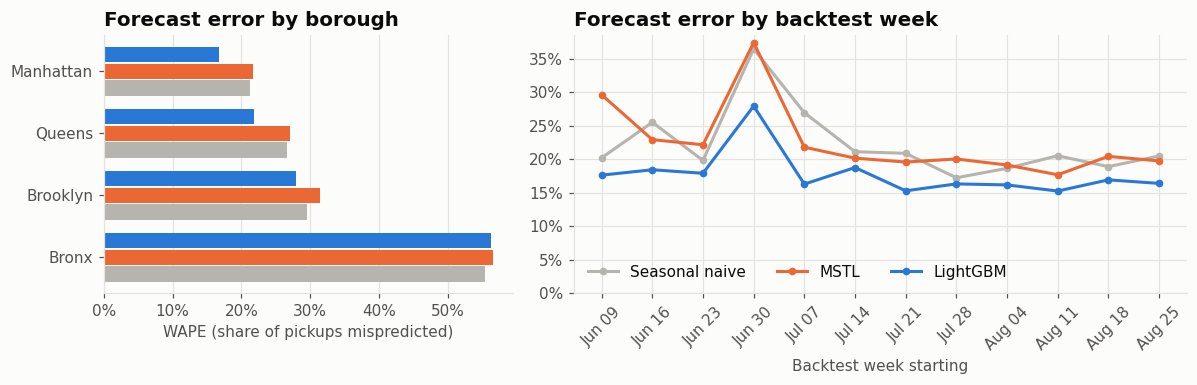

In [11]:
# 4.6 Figure 4.1, error by borough and by backtest week
MAIN = ["Seasonal naive", "MSTL", "LightGBM"]                # the post-Jan 2025 variant stays in the tables
MC = {"Seasonal naive": "#b5b4ae", "MSTL": C[1], "LightGBM": C[0]}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2, 3]})

boros = by_borough.WAPE.unstack().loc[:, MAIN]
boros = boros.loc[[b for b in ["Manhattan", "Queens", "Brooklyn", "Bronx"] if b in boros.index]]
yb = np.arange(len(boros))
for i, m in enumerate(MAIN):
    a1.barh(yb + (1 - i) * 0.27, boros[m], height=0.25, color=MC[m], label=m)
a1.set_yticks(yb, boros.index)
a1.invert_yaxis()
a1.grid(axis="y", visible=False)
a1.xaxis.set_major_locator(mtick.MultipleLocator(0.05))
a1.xaxis.set_major_locator(mtick.MaxNLocator(6, steps=[1, 2, 5, 10]))
a1.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
a1.set_xlabel("WAPE (share of pickups mispredicted)")
a1.set_title("Forecast error by borough")

for m in MAIN:
    a2.plot(by_week.index, by_week[m], color=MC[m], marker="o", markersize=4, label=m)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
a2.set_ylim(bottom=0)
a2.set_xlabel("Backtest week starting")
a2.tick_params(axis="x", labelrotation=45)
a2.legend(loc="lower left", ncol=3)
a2.set_title("Forecast error by backtest week")
save(fig, "13_forecast_error")

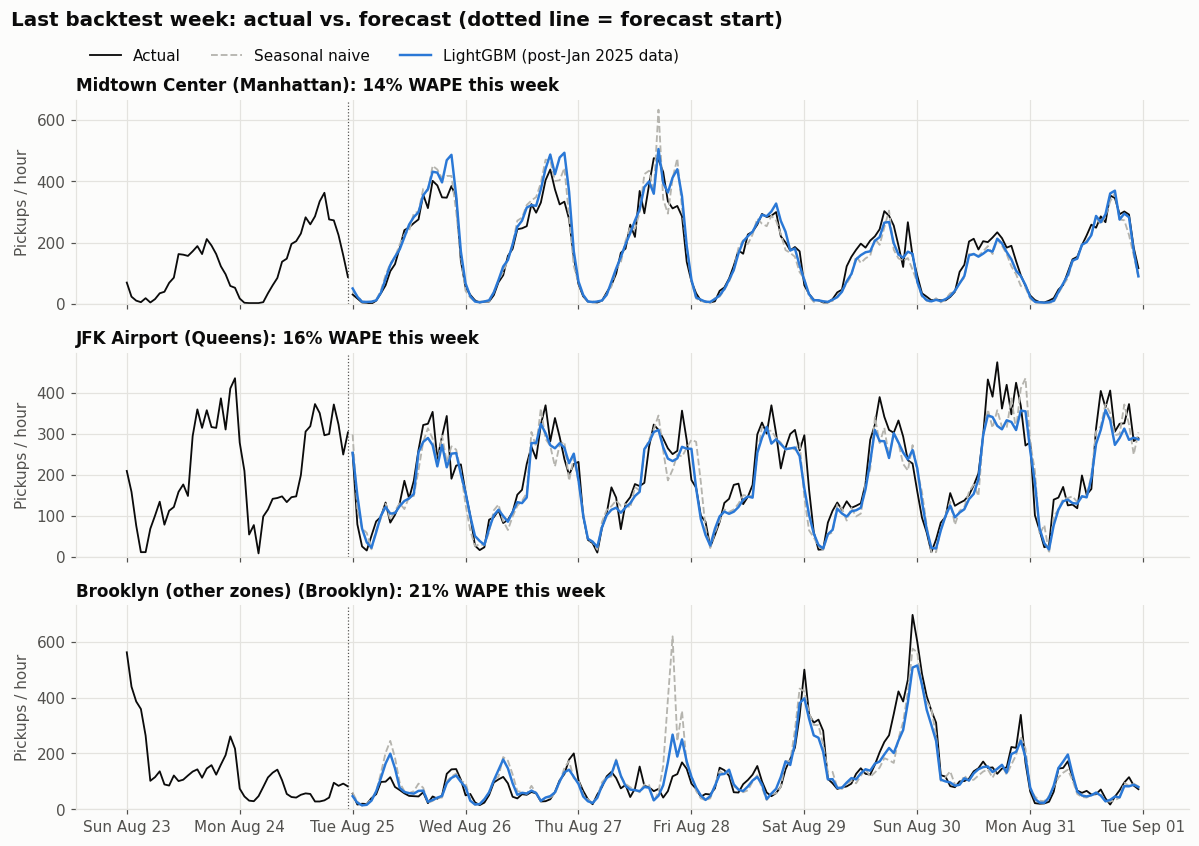

In [9]:
# 4.6 Figure 4.2, actual vs. forecast for Midtown, JFK and the busiest outer-borough zone,
# over the last backtest week.
def pick_outer():
    outer = [u for u in info.index if u.startswith("z") and BOROUGH[u] not in ("Manhattan", "EWR")
             and u not in ("z132", "z138")]
    if outer:
        return max(outer, key=lambda u: series.loc[series.unique_id == u, "y"].sum())
    return "other_Brooklyn"

show = [u for u in ["z161", "z132"] if u in info.index] + [pick_outer()]
last_c = CUTOFFS[-1]
fig, axes = plt.subplots(len(show), 1, figsize=(11, 2.6 * len(show)), sharex=True)
for ax, u in zip(np.atleast_1d(axes), show):
    ctx = series[(series.unique_id == u) & (series.ds > last_c - pd.Timedelta(days=2)) & (series.ds <= last_c)]
    win = cv[(cv.unique_id == u) & (cv.cutoff == last_c)]
    ax.plot(ctx.ds, ctx.y, color=INK, lw=1.2)
    ax.plot(win.ds, win.y, color=INK, lw=1.2, label="Actual")
    ax.plot(win.ds, win["Seasonal naive"], color=MC["Seasonal naive"], lw=1.2, ls="--", label="Seasonal naive")
    ax.plot(win.ds, win[BEST], color=C[0], lw=1.6, label=BEST)
    ax.axvline(last_c, color=INK2, lw=0.8, ls=":")
    ax.set_ylim(bottom=0)
    ax.set_ylabel("Pickups / hour")
    w = (win[BEST] - win.y).abs().sum() / win.y.sum()
    ax.set_title(f"{LABEL[u]} ({BOROUGH[u]}): {w:.0%} WAPE this week", fontsize=11)
np.atleast_1d(axes)[0].legend(loc="upper left", ncol=3, bbox_to_anchor=(0, 1.32))
np.atleast_1d(axes)[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %b %d"))
fig.suptitle("Last backtest week: actual vs. forecast (dotted line = forecast start)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
save(fig, "14_forecast_examples")

In [10]:
# 4.7 Forecast the next 7 days with the best model and save the result for the dashboard.
last = series.ds.max()
future_ds = pd.date_range(last + pd.Timedelta(hours=1), periods=H, freq="h")
if BEST == "MSTL":
    fc = sf.forecast(df=series[["unique_id", "ds", "y"]].groupby("unique_id").tail(MSTL_INPUT_WEEKS * H), h=H)
    fc = fc.rename(columns={"MSTL": "forecast"})[["unique_id", "ds", "forecast"]]
else:
    full = panel[panel.lag_672.notna()]
    if BEST.startswith("LightGBM (post"):
        full = full[full.ds >= "2025-01-05"]
    final = lgb.train(LGB_PARAMS, lgb.Dataset(full[FEATURES], full.y), num_boost_round=NUM_ROUNDS)
    grid = pd.MultiIndex.from_product([info.index, future_ds], names=["unique_id", "ds"]).to_frame(index=False)
    ext = add_features(pd.concat([series[["unique_id", "ds", "y"]], grid.assign(y=np.nan)]))
    fut = ext[ext.ds > last]
    assert fut[FEATURES].drop(columns="series").notna().all().all(), "future rows are missing lag features"
    fc = fut[["unique_id", "ds"]].assign(forecast=final.predict(fut[FEATURES]))
    final.save_model(str(MODELS / "demand_lgb.txt"))

fc = fc.assign(forecast=fc.forecast.clip(lower=0).round(1), label=fc.unique_id.map(LABEL),
               borough=fc.unique_id.map(BOROUGH), model=BEST, made_at=pd.Timestamp.now().floor("s"))
fc.to_parquet(AGG / "forecast_zone_hour.parquet", index=False)

con.close()                                     # reopen writable once to register the view for Phase 5
db = duckdb.connect(str(BASE / "taxi.duckdb"))
db.execute(f"CREATE OR REPLACE VIEW forecast_zone_hour AS SELECT * FROM '{AGG}/forecast_zone_hour.parquet'")
db.close()
con = duckdb.connect(str(BASE / "taxi.duckdb"), read_only=True)
print(f"{len(fc):,} forecasts ({fc.ds.min():%a %b %d %H:00} to {fc.ds.max():%a %b %d %H:00}) saved by {BEST}")
con.sql("SELECT label, sum(forecast)::INT AS pickups_next_7_days FROM forecast_zone_hour "
        "GROUP BY 1 ORDER BY 2 DESC LIMIT 10").df()

9,408 forecasts (Tue Sep 01 00:00 to Mon Sep 07 23:00) saved by LightGBM (post-Jan 2025 data)


,label,pickups_next_7_days
0,Upper East Side South,34825
1,Midtown Center,33977
2,JFK Airport,33066
3,Upper East Side North,28377
4,Penn Station/Madison Sq West,28340
5,Midtown East,25056
6,East Village,25003
7,Brooklyn (other zones),24909
8,Manhattan (other zones),24459
9,Times Sq/Theatre District,23529


In [12]:
metrics = {"overall": overall.round(4).to_dict(orient="index"),
           "by_borough_WAPE": by_borough.WAPE.unstack().round(4).to_dict(orient="index"),
           "best_model": BEST,
           "config": {"top_n": TOP_N, "horizon_h": H, "windows": N_WINDOWS, "first_cutoff": str(CUTOFFS[0]),
                      "last_cutoff": str(CUTOFFS[-1]), "mstl_input_weeks": MSTL_INPUT_WEEKS,
                      "lgb_rounds": NUM_ROUNDS, **{k: LGB_PARAMS[k] for k in ["learning_rate", "num_leaves"]}}}
(MODELS / "forecast_backtest.json").write_text(json.dumps(metrics, indent=2, default=str))

run = {"run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "top_n": TOP_N, "windows": N_WINDOWS,
       "last_cutoff": str(CUTOFFS[-1]), "lgb_rounds": NUM_ROUNDS, "num_leaves": LGB_PARAMS["num_leaves"],
       **{f"{m} MASE": round(overall.MASE[m], 3) for m in MODEL_COLS},
       **{f"{m} WAPE": round(overall.WAPE[m], 4) for m in MODEL_COLS}, "best": BEST}
log_path = MODELS / "forecast_log.csv"
pd.DataFrame([run]).to_csv(log_path, mode="a", header=not log_path.exists(), index=False)
print(json.dumps(metrics["overall"], indent=2))
pd.read_csv(log_path).tail()

{
  "Seasonal naive": {
    "MASE": 0.8953,
    "WAPE": 0.2206,
    "MAE (pickups/hour)": 17.571
  },
  "MSTL": {
    "MASE": 0.8884,
    "WAPE": 0.2254,
    "MAE (pickups/hour)": 17.956
  },
  "LightGBM": {
    "MASE": 0.7345,
    "WAPE": 0.177,
    "MAE (pickups/hour)": 14.1031
  },
  "LightGBM (post-Jan 2025 data)": {
    "MASE": 0.7329,
    "WAPE": 0.1767,
    "MAE (pickups/hour)": 14.0783
  }
}


,run_at,top_n,windows,last_cutoff,lgb_rounds,num_leaves,Seasonal naive MASE,MSTL MASE,LightGBM MASE,LightGBM (post-Jan 2025 data) MASE,Seasonal naive WAPE,MSTL WAPE,LightGBM WAPE,LightGBM (post-Jan 2025 data) WAPE,best
0,2026-10-19 22:27,50,12,2026-08-24 23:00:00,600,63,0.895,0.888,0.735,0.733,0.2206,0.2254,0.177,0.1767,LightGBM (post-Jan 2025 data)
